In [1]:
import torch
from IPython import display
from d2l import torch as d2l

batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size)

100.0%
100.0%
100.0%
100.0%


In [ ]:
# 每个图像大小为1*28*28，拉长后变为784，输出类别数为10
num_inputs = 784
num_outputs = 10
# y = XW + b, X的形状为(batch_size, 784)，W的形状为(784, 10)，b的形状为(10, )，y的形状为(batch_size, 10)
W = torch.normal(0, 0.01, size=(num_inputs, num_outputs), requires_grad=True)
b = torch.zeros(num_outputs, requires_grad=True)

In [3]:
# 实现Softmax
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(1, keepdim=True)
    return X_exp / partition  # 这里应用了广播机制

In [5]:
X = torch.normal(0, 1, (2, 5))
X_prob = softmax(X)
print(X_prob)
X_prob.sum(1)  # 沿着列的方向求和，结果为1

tensor([[0.4295, 0.1135, 0.2912, 0.0237, 0.1420],
        [0.0646, 0.0921, 0.1619, 0.5826, 0.0988]])


tensor([1.0000, 1.0000])

In [6]:
# 实现softmax回归模型
def net(X):
    return softmax(torch.matmul(X.reshape((-1, W.shape[0])), W) + b)

In [8]:
y = torch.tensor([0, 2])    # 两个样本的类型分别是0、2
y_hat = torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]]) # 预测的两个样本的类别概率分布
y_hat[[0, 1], y]  # 预测正确类别的概率

tensor([0.1000, 0.5000])

In [9]:
# 实现交叉熵损失函数，预测的越不准确，损失越大
def cross_entropy(y_hat, y):
    return -torch.log(y_hat[range(len(y_hat)), y])

cross_entropy(y_hat, y)

tensor([2.3026, 0.6931])

In [10]:
# 返回预测正确的数量
def accuracy(y_hat, y):
    # y_hat是二维的且类别数大于1时，取每一行最大值的列索引作为预测类别
    if len(y_hat.shape) > 1 and y_hat.shape[1] > 1:
        y_hat = y_hat.argmax(axis=1)
    # 将y_hat的数据类型转换成y的，并进行比较
    cmp = (y_hat.type(y.dtype) == y)
    return float(cmp.type(y.dtype).sum())

accuracy(y_hat, y) / len(y)  # 计算准确率

0.5

In [13]:
def evaluate_accuracy(net, data_iter):
    """计算在指定数据集上模型的精度"""
    if isinstance(net, torch.nn.Module):
        net.eval()  # 将模型设置为评估模式
    metric = d2l.Accumulator(2)  # 累加器，存储：[正确预测数，预测总数]
    for X, y in data_iter:
        metric.add(accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]

evaluate_accuracy(net, test_iter)

0.0727

In [ ]:
# 训练模型
def train_epoch_ch3(net, train_iter, loss, updater):
    if isinstance(net, torch.nn.Module):
        net.train()  # 如果是标准的Pytorch模型，则将模型设置为训练模式
    metric = d2l.Accumulator(3)  # 训练损失总和，正确预测数，样本数
    for X, y in train_iter:
        y_hat = net(X)  # 1、前向传播，得到预测概率
        l = loss(y_hat, y)  # 2、计算当前batch的损失
        if isinstance(updater, torch.optim.Optimizer):
            """分支A:标准PyTorch优化器"""
            updater.zero_grad() # 3、梯度清零
            l.backward()    # 4、反向传播，计算梯度
            updater.step()  # 5、更新参数(W, b)
            metric.add(
                float(l) * len(y),  # 累加训练损失
                accuracy(y_hat, y),  # 累加正确预测数
                y.size().numel()  # 累加样本数,直接.numel()则会返回张量中元素的总数
            )
        else:
            """分支B:自定义优化器"""
            l.sum().backward()  # 3、反向传播
            updater(X.shape[0])  # 4、更新参数(W, b)，传入batch_size
            metric.add(
                float(l.sum()),  # 累加训练损失
                accuracy(y_hat, y),  # 累加正确预测数
                y.size().numel()  # 累加样本数
            )
    # 返回平均损失和准确率
    return metric[0] / metric[2], metric[1] / metric[2]  

In [17]:
# 训练模型
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):
    # 初始化动画绘制器
    animator = d2l.Animator(xlabel='epoch', xlim=[1, num_epochs], legend=['train loss', 'train acc', 'test acc'])
    for epoch in range(num_epochs):
        # 训练模型一个迭代周期
        train_metrics = train_epoch_ch3(net, train_iter, loss, updater)
        # 评估模型在测试集上的准确率
        test_acc = evaluate_accuracy(net, test_iter)
        # 更新动画绘制器
        animator.add(epoch + 1, train_metrics + (test_acc,))
    # 解包训练损失和准确率
    train_loss, train_acc = train_metrics
    

In [18]:
lr = 0.1

def updater(batch_size):
    return d2l.sgd([W, b], lr, batch_size)

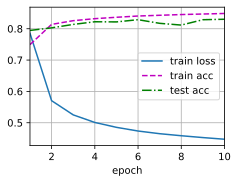

In [19]:
# 训练模型10个迭代周期
num_epochs = 10
train_ch3(net, train_iter, test_iter, cross_entropy, num_epochs, updater);

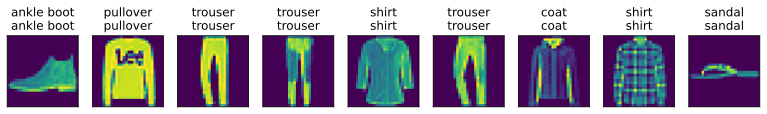

In [21]:
# 用训好的模型进行预测，并将结果可视化
def predict_ch3(net, test_iter, n=9):
    for X, y in test_iter:  # 只取一个batch的样本进行预测
        break
    # 将数字标签y转换成文本标签，存在trues里
    trues = d2l.get_fashion_mnist_labels(y)  
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))  # 获取预测标签
    # 将真实标签和预测标签拼接在一起，作为标题
    titles = [true + '\n' + pred for true, pred in zip(trues, preds)]
    d2l.show_images(
        X[0:n].reshape((n, 28, 28)), 1, n, titles=titles[0:n]
    )
predict_ch3(net, test_iter)  # 预测前9个样本